# Truncated SVD

Every matrix factors as `X = U · S · Vᵀ`: `V` holds orthonormal directions in feature space, `S` the strength of each, `U` the coordinates of each sample. Keep only the `k` largest singular values and you get the **best rank-`k` approximation of `X`** (Eckart–Young): no other rank-`k` matrix is closer.

## How it works

1. Form the Gram matrix `XᵀX`. Its eigenvalues are the squared singular values `s²`, its eigenvectors the right singular vectors `V`.
2. Sort descending, keep the top `k`: `components_` is `Vₖᵀ`, `singular_values_` is `sₖ`.
3. `transform(X) = X · Vₖ` (this is `Uₖ Sₖ`); `inverse_transform(Z) = Z · Vₖᵀ` is the rank-`k` reconstruction.
4. Reconstruction error is exactly `Σ s²` over the dropped values — the test checks this.

## SVD vs PCA

PCA = SVD of the **centered** data. `TruncatedSVD` skips the centering, so it works on data where zero means "nothing there" (word counts, tf-idf, ratings) and the mean is not a meaningful origin. If your data has a big offset, the first SVD component just points at the mean — that is what centering in PCA removes.

Common uses: latent semantic analysis (documents × terms), image compression, denoising, matrix completion building block.

`ponytail:` this builds `XᵀX`, which squares the condition number and costs `O(n·d²)`. For big or ill-conditioned matrices use `np.linalg.svd` or a randomized/Lanczos solver.

## Usage

```python
# (the class is defined in the Implementation section below)

svd = TruncatedSVD(n_components=10).fit(X)
Z = svd.transform(X)               # n x 10
X_approx = svd.inverse_transform(Z)  # rank-10 reconstruction
svd.singular_values_, svd.explained_variance_ratio_
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


class TruncatedSVD:
    """Best rank-k approximation X ~ U S Vt, keeping the k largest singular values.

    Same as PCA except the data is NOT centered first, so it also works on data where zero means
    "absent" (word counts, tf-idf, ratings). Eckart-Young: no other rank-k matrix is closer to X.

    Computed from the eigendecomposition of the Gram matrix XtX: its eigenvalues are the squared
    singular values and its eigenvectors are the right singular vectors V.

    ponytail: forming XtX squares the condition number (tiny singular values lose precision) and
    costs O(n d^2); use np.linalg.svd or a randomized/Lanczos solver for big or ill-conditioned X."""

    def __init__(self, n_components=2):
        self.n_components = n_components

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        eigenvalues, eigenvectors = np.linalg.eigh(X.T @ X)
        order = np.argsort(eigenvalues)[::-1][: self.n_components]
        self.singular_values_ = np.sqrt(np.maximum(eigenvalues[order], 0.0))
        self.components_ = eigenvectors[:, order].T  # rows are the right singular vectors
        Z = X @ self.components_.T  # = U S
        self.explained_variance_ = Z.var(axis=0)
        self.explained_variance_ratio_ = self.explained_variance_ / X.var(axis=0).sum()
        return self

    def transform(self, X):
        return np.asarray(X, dtype=float) @ self.components_.T

    def fit_transform(self, X):
        return self.fit(X).transform(X)

    def inverse_transform(self, Z):
        """Map k-dim coordinates back to the original space (the rank-k reconstruction)."""
        return np.asarray(Z, dtype=float) @ self.components_

## See it work

### 1. Compressing an image

A grayscale image is just a matrix. A rank-`k` approximation keeps only the `k` strongest "layers" (each an outer product `uᵢ sᵢ vᵢᵀ`). The smaller `k` is, the more compression and the blurrier the picture; a few dozen layers already look close to the original.

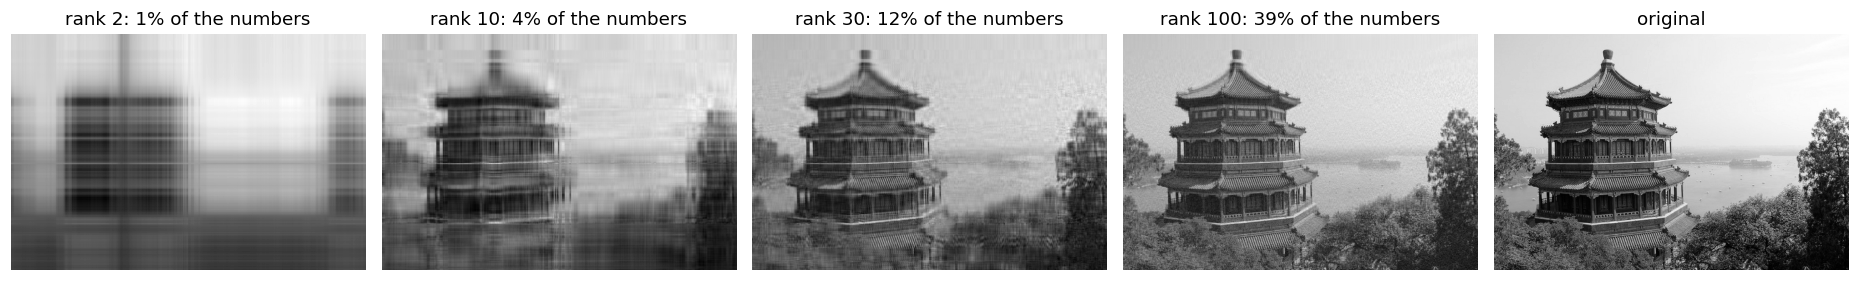

In [3]:
from sklearn.datasets import load_sample_image

img = load_sample_image("china.jpg").mean(axis=2)            # grayscale, 427 x 640
fig, axes = plt.subplots(1, 5, figsize=(17, 3.4))
for ax, k in zip(axes, [2, 10, 30, 100]):
    svd = TruncatedSVD(n_components=k).fit(img)
    rec = svd.inverse_transform(svd.transform(img))
    ax.imshow(rec, cmap="gray"); ax.set_title(f"rank {k}: {k * sum(img.shape) / img.size:.0%} of the numbers"); ax.axis("off")
axes[4].imshow(img, cmap="gray"); axes[4].set_title("original"); axes[4].axis("off")
plt.tight_layout(); plt.show()

### 2. The singular value spectrum

Singular values say how much each layer contributes. They decay fast for natural images: the first few carry most of the energy, which is why low-rank compression works. The error of a rank-`k` approximation is exactly the sum of the *discarded* squared singular values (Eckart-Young).

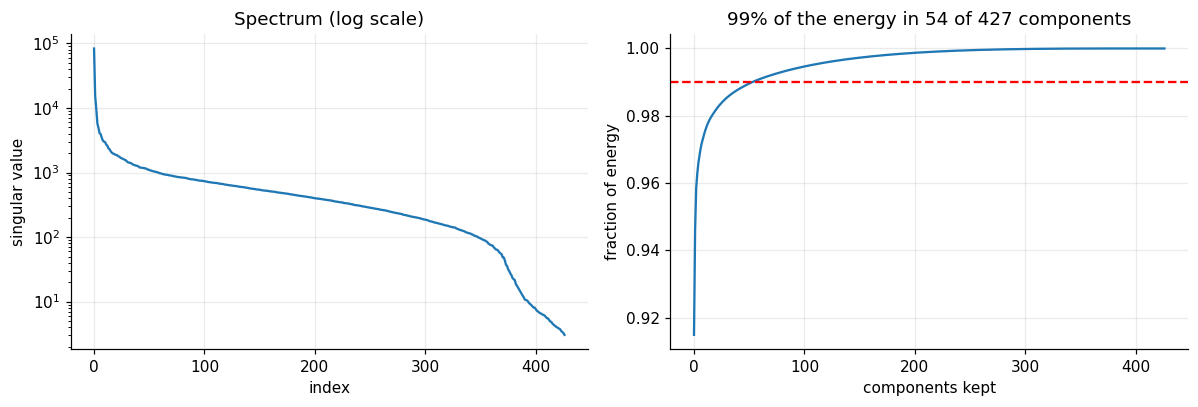

In [4]:
full = TruncatedSVD(n_components=min(img.shape)).fit(img)
s = full.singular_values_
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8))
a.semilogy(s); a.set(xlabel="index", ylabel="singular value", title="Spectrum (log scale)")
energy = np.cumsum(s ** 2) / np.sum(s ** 2)
b.plot(energy); b.axhline(0.99, color="r", ls="--"); b.set(xlabel="components kept", ylabel="fraction of energy", title=f"99% of the energy in {int(np.searchsorted(energy, 0.99)) + 1} of {len(s)} components")
plt.tight_layout(); plt.show()

### 3. SVD is PCA without the centring step

PCA subtracts the mean first; Truncated SVD does not, so it also works on data where zero is meaningful (counts, tf-idf), and it can be applied to sparse matrices without destroying sparsity. If the data sits far from the origin, the first SVD component simply points at the mean:

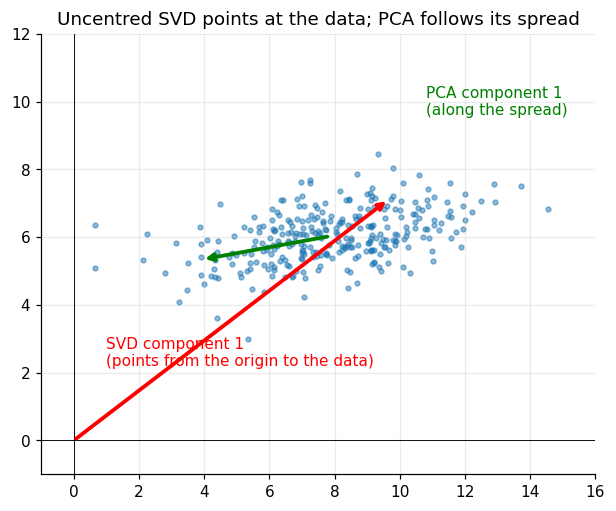

In [5]:
rng = np.random.default_rng(0)
X = rng.normal(size=(300, 2)) @ np.array([[2.0, 0.0], [1.0, 0.8]]) + np.array([8.0, 6.0])
svd = TruncatedSVD(n_components=2).fit(X)
Xc = X - X.mean(0); _, vecs = np.linalg.eigh(np.cov(Xc.T)); pc1 = vecs[:, -1]
v = svd.components_[0] * np.sign(svd.components_[0] @ X.mean(0))           # flip sign so the arrow points toward the data
plt.figure(figsize=(6.5, 5.2)); plt.scatter(*X.T, s=10, alpha=0.5)
plt.annotate("", xy=v * 12, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="r", lw=2.5)); plt.text(1.0, 2.2, "SVD component 1\n(points from the origin to the data)", color="r")
plt.annotate("", xy=X.mean(0) + pc1 * 4, xytext=X.mean(0), arrowprops=dict(arrowstyle="->", color="g", lw=2.5)); plt.text(10.8, 9.6, "PCA component 1\n(along the spread)", color="g")
plt.axhline(0, color="k", lw=0.6); plt.axvline(0, color="k", lw=0.6); plt.xlim(-1, 16); plt.ylim(-1, 12); plt.title("Uncentred SVD points at the data; PCA follows its spread"); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [6]:
import numpy as np
from sklearn.datasets import load_digits
from sklearn.decomposition import TruncatedSVD as SklearnSVD

X = load_digits().data

ours = TruncatedSVD(n_components=10).fit(X)
theirs = SklearnSVD(n_components=10, algorithm="arpack", random_state=0).fit(X)

print("singular values (top 3): ours=%s sklearn=%s" % (ours.singular_values_[:3].round(3), theirs.singular_values_[:3].round(3)))
assert np.allclose(ours.singular_values_, theirs.singular_values_, atol=1e-6)
assert np.allclose(ours.explained_variance_ratio_, theirs.explained_variance_ratio_, atol=1e-6)
assert np.allclose(np.abs(ours.transform(X)), np.abs(theirs.transform(X)), atol=1e-6)  # sign is arbitrary
print("projections match sklearn up to sign")

print("rank-k reconstruction error of the 64-pixel digits:")
for k in (2, 5, 10, 20, 40):
    model = TruncatedSVD(n_components=k).fit(X)
    error = np.linalg.norm(X - model.inverse_transform(model.transform(X))) / np.linalg.norm(X)
    print("  k=%2d  relative error %.3f" % (k, error))

singular values (top 3): ours=[2193.119  566.997  542.005] sklearn=[2193.119  566.997  542.005]
projections match sklearn up to sign
rank-k reconstruction error of the 64-pixel digits:


  k= 2  relative error 0.507


  k= 5  relative error 0.389


  k=10  relative error 0.289


  k=20  relative error 0.182


  k=40  relative error 0.061


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [7]:
import numpy as np


def test_singular_values_match_numpy_svd():
    X = np.random.default_rng(0).normal(size=(60, 6))
    model = TruncatedSVD(n_components=6).fit(X)
    assert np.allclose(model.singular_values_, np.linalg.svd(X, compute_uv=False), atol=1e-8)


def test_reconstruction_error_is_sum_of_discarded_squared_singular_values():
    # Eckart-Young: ||X - X_k||_F^2 = sum of the squared singular values we dropped
    X = np.random.default_rng(1).normal(size=(80, 7))
    s = np.linalg.svd(X, compute_uv=False)
    model = TruncatedSVD(n_components=3).fit(X)
    error = ((X - model.inverse_transform(model.transform(X))) ** 2).sum()
    assert np.isclose(error, (s[3:] ** 2).sum())


def test_exact_when_data_is_low_rank():
    rng = np.random.default_rng(2)
    X = rng.normal(size=(50, 2)) @ rng.normal(size=(2, 8))  # rank 2
    model = TruncatedSVD(n_components=2).fit(X)
    assert np.allclose(model.inverse_transform(model.transform(X)), X, atol=1e-8)


def test_components_orthonormal_and_data_not_centered():
    X = np.random.default_rng(3).normal(size=(40, 5)) + 100.0   # huge offset
    model = TruncatedSVD(n_components=3).fit(X)
    assert np.allclose(model.components_ @ model.components_.T, np.eye(3), atol=1e-8)
    # the offset dominates, so component 0 points along the mean direction (what PCA would remove)
    mean_dir = X.mean(axis=0) / np.linalg.norm(X.mean(axis=0))
    assert abs(model.components_[0] @ mean_dir) > 0.99

In [8]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_singular_values_match_numpy_svd
PASS test_reconstruction_error_is_sum_of_discarded_squared_singular_values
PASS test_exact_when_data_is_low_rank
PASS test_components_orthonormal_and_data_not_centered

all 4 tests passed


## Takeaways

- **Use it for** low-rank approximation (compression, denoising), latent semantic analysis on tf-idf matrices, recommenders (matrix factorisation), and as the numerical engine behind PCA, least squares and the pseudo-inverse.
- **Key facts:** `X = U S Vᵀ`; the rank-`k` truncation is the best rank-`k` approximation in Frobenius and spectral norm (Eckart-Young); `PCA = SVD(X − mean)`.
- **This version** eigendecomposes `XᵀX` (squares the condition number, `O(n·d²)`); real libraries use LAPACK `gesdd`, or randomised/Lanczos methods for large sparse matrices.
- **Interview line:** *"Truncated SVD keeps the top-k singular triplets: best low-rank approximation, no centring (unlike PCA), works on sparse non-negative data."*